# EDA

## Ogólne spojrzenie na zebrane dane

In [5]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Ścieżka do folderu, w którym są wszystkie kategorie
base_path = "../data/training_set"

In [ ]:
# Lista folderów (kategorii)
categories = [
    d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))
]

# Zliczamy liczbę plików w każdym folderze
data = []
for category in categories:
    folder_path = os.path.join(base_path, category)
    file_count = len(
        [
            f
            for f in os.listdir(folder_path)
            if os.path.isfile(os.path.join(folder_path, f))
        ]
    )
    data.append({"category": category, "file_count": file_count})

# Tworzymy DataFrame
df = pd.DataFrame(data)

# Podgląd
df

,category,file_count
0,city_daylight,6044
1,city_daylight_rain,958
2,city_night,924
3,city_night_rain,378
4,highway_daylight,1393
5,highway_daylight_rain,336
6,highway_night,238
7,highway_night_rain,42
8,mountain_roads_daylight,819
9,mountain_roads_daylight_rain,151


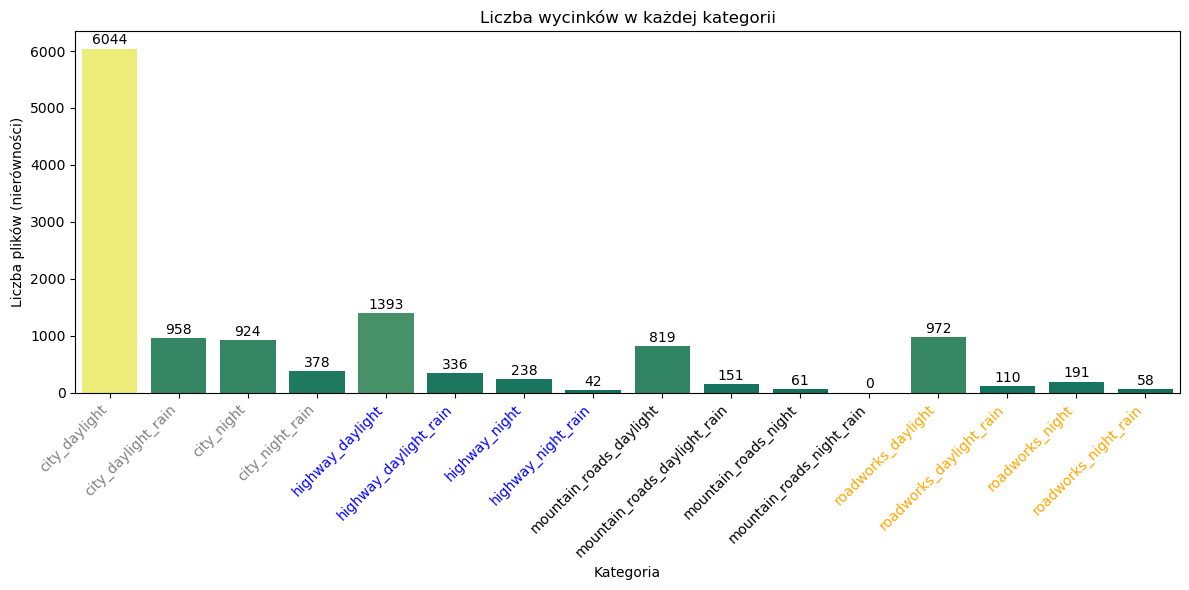

In [ ]:
prefix_colors = {
    "city": "grey",
    "highway": "blue",
    "mountain_roads": "green",
    "roadworks": "orange",
}

df["prefix"] = df["category"].apply(lambda x: x.split("_")[0])

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=df,
    x="category",
    y="file_count",
    hue="file_count",
    palette="summer",
    legend=False,
)
ax.set(
    title="Liczba wycinków w każdej kategorii",
    xlabel="Kategoria",
    ylabel="Liczba plików (nierówności)",
)

# Pokoloruj xtick labels na podstawie prefixu
xtick_labels = ax.get_xticklabels()
for label in xtick_labels:
    category = label.get_text()
    prefix = category.split("_")[0]
    label.set_color(prefix_colors.get(prefix, "black"))  # domyślny kolor to czarny

plt.xticks(rotation=45, ha="right")

for container in ax.containers:
    ax.bar_label(container, label_type="edge", padding=1)

plt.tight_layout()
plt.show()

In [32]:
df["file_count"].sum()

np.int64(12675)